## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('/content/sample_data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()


Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

Unique tokens: 48691
Tokens appearing once: 29404
Most common: [('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


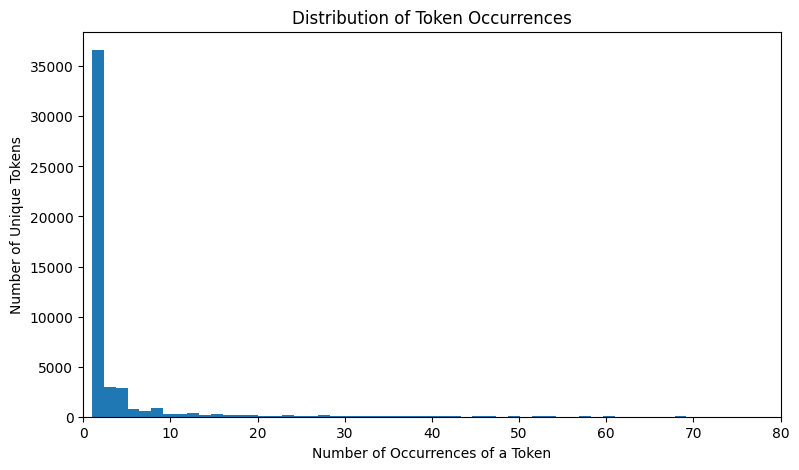


Q2.1
(18634, 2711) {0: 11322, 1: 7312}

2.2

Q2 Train R^2: 0.7680301260237321
Q2 Test R^2:  0.6587519780798341

Top 20 coefficients by absolute value:
                token      coef
0   background-image: -0.891476
1           localized  0.815698
2          helvetica,  0.717349
3             thermal  0.706216
4               aging  0.622411
5          transcript  0.578132
6             april's -0.546313
7          retrieving -0.527824
8                cnet -0.510492
9               zdnet -0.503465
10             xanaax  0.503086
11             arial, -0.485267
12       intervention -0.450524
13  {text-decoration:  0.449816
14              form.  0.442778
15             rhythm  0.441920
16              none; -0.437793
17             issue: -0.436110
18             ï¿½ï¿½  0.430259
19         girlfriend  0.419372
          token      coef      freq    impact
21         url: -0.410263  0.033743 -0.013843
143       enron -0.225298  0.037432 -0.008433
344      wrote: -0.165290  0.029248 -0


Q4

Q4 Train R^2: 0.7673333826623814
Q4 Test R^2:  0.6597095337756083


In [4]:
import pickle, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

base = "https://raw.githubusercontent.com/elijahschoeniger-cpu/A05-pca/main/data/"
df = pd.read_parquet(base + "Phishing_clean.parquet")
with urllib.request.urlopen(base + "all_tokens.pickle") as f:
    all_tokens = pickle.load(f)

#Kept getting runtime and file loading issues so I had to pull directly from git.

# Q1

#Token freqs are extremely skewed to the right, the vast majority appear only once or a handful of times while a few appear quite a much larger number of times.
#Most common tokens displayed are "new", "date", "get", "please", and "enron"(makes absolutely no sense.) Of our 48691 tokens it's apparent none were counted in my unique token call even though
#the histogram and dataset seem to directly contradict that.


token_count = Counter(all_tokens)
token_freq = token_count.most_common()
counts = [c for _, c in token_freq]

print('Unique tokens:', len(token_freq))
print('Tokens appearing once:', sum(c == 1 for c in counts))
print('Most common:', token_freq[:10])

plt.figure(figsize=(9, 5))
plt.hist(counts, bins=1000)
plt.xlabel('Number of Occurrences of a Token')
plt.ylabel('Number of Unique Tokens')
plt.title('Distribution of Token Occurrences')
plt.xlim(0, 80)
plt.show()

# Q2.1
# The set has 18634 emails with 2711 token features 11322 are safe 7312 are scams, 14907 in training with 3727 in test.
print("")
print("Q2.1")
y = df['Email Type'].astype(int)
X = df.drop(columns=['Email Type']).select_dtypes(include=[np.number, bool]).astype(float)
print(X.shape, y.value_counts().to_dict())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

# Q2.2
#Training R square is 0.768 and the test is 0.659. Model is capturing ~77 percent of training variation and ~66 percent of the variance on test emails.
#With the 2711 features OLS is probably fitting training specific emails which which probably explains the overfitting drop in performance.

print("")
print("2.2")
reg = LinearRegression().fit(X_train, y_train)
print('\nQ2 Train R^2:', reg.score(X_train, y_train))
print('Q2 Test R^2: ', reg.score(X_test, y_test))

# Q2.3
# Pos = Scam and Neg = Safe
# Most of the largest coefficients are HTML formatting tokens, and then relatively uncommon words. ie #1 = Background-Image at -0.89, #2 localized, and #3 helvetica.
# What I then did to try to find the actual impact of the token was to multiply it by the fraction of emails that contained the token
# Leaving us with a new top 5 of: url, enron, wrote, empty, and original.

coefs = pd.DataFrame({'token': X.columns, 'coef': reg.coef_})
coefs = coefs.iloc[coefs['coef'].abs().argsort()[::-1]].reset_index(drop=True)
print('\nTop 20 coefficients by absolute value:')
print(coefs.head(20).to_string())

coefs['freq'] = X_train[coefs['token']].mean().values
coefs['impact'] = coefs['coef'] * coefs['freq']
print(coefs.reindex(coefs['impact'].abs().sort_values(ascending=False).index).head(20))

# Q3
# The first two principal components explain a cumululative ~2% of variance, PC1 = 1.1% and PC2 = 0.9% respectively. Some patterns appear though no small number of dimensions will summarize this well
#because of the high numbers of dimensions. Most of the set falls into a dense cluster near the origin with the phishing emails appearing higher and the safe emails appearing lower on PC2. That being
#said there is a huge amount of overlap. When we look at the clusters of tokens on each end, PC1 kind of looks like a spectrum of how "enron" the message is -/+ and PC2 is basically an axis of how sales spammy the email is.
#
print("")
print("Q3")
loadings = pd.DataFrame(pca2.components_.T, index=X.columns, columns=['PC1', 'PC2'])
for pc in ['PC1', 'PC2']:
    s = loadings[pc].sort_values()
    print(f'{pc} most positive:', s.tail(10)[::-1].index.tolist())
    print(f'{pc} most negative:', s.head(10).index.tolist())

regions = {
    'Main blob (PC1 < 0.1)': pca_df['PC1'] < 0.1,
    'Cluster ~0.1-0.45': pca_df['PC1'].between(0.1, 0.45),
    'Cluster ~0.45-0.8': pca_df['PC1'].between(0.45, 0.8),
    'Cluster ~1.0+': pca_df['PC1'] > 0.85,
}
for name, mask in regions.items():
    m = mask.values
    print(f'\n{name}: {m.sum()} emails, {y[m].mean():.1%} phishing')
    print('Most common words:', X[m].mean().sort_values(ascending=False).head(10).index.tolist())

blob = pca_df['PC1'] < 0.1
print('\nMain blob phishing rate, PC2 > 0:', round(y[(blob & (pca_df['PC2'] > 0)).values].mean(), 3))
print('Main blob phishing rate, PC2 < 0:', round(y[(blob & (pca_df['PC2'] < 0)).values].mean(), 3))

plot_df = pca_df.copy()
plot_df['Email Type'] = y.map({0: 'Safe', 1: 'Phishing'}).values
fig = px.scatter(plot_df, x='PC1', y='PC2', color='Email Type', opacity=0.5,
                 color_discrete_map={'Safe': 'royalblue', 'Phishing': 'crimson'},
                 title='First Two Principal Components',
                 labels={'PC1': f'Principal Component 1 ({ev[0]:.1%} of variance)',
                         'PC2': f'Principal Component 2 ({ev[1]:.1%} of variance)'},
                 width=1000, height=550)
fig.update_layout(legend=dict(x=0.85, y=0.98, bgcolor='rgba(255,255,255,0.8)'))
fig.show()


# Q4
# By regressing y on 2610 pc we get a training R squared of 0.767 and a test of 0.660 which is near identical to our OLS regression which has a train of 0.768 and a test of 0.659.
#Training drops by .001 and test rises by about .001 so the gap closes ever so slightly. 2610 is about 96% of the original 2711 so the near identical results seems logical, the dropped components
#were more than likely just capturing noise, and their removal costs basically nothing. Keeping the full 2610 doesnt reduce overfitting though since our train test gaps barely changed.
print("")
print("Q4")
pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)
reg_pca = LinearRegression().fit(Z_train, y_train)
print('\nQ4 Train R^2:', reg_pca.score(Z_train, y_train))
print('Q4 Test R^2: ', reg_pca.score(Z_test, y_test))

#Q5
# Principal components are uncorrelated with one another and the original token features are highly correlated. Words that generally go together such as "background-image" being paired with "helvetica"
# made OLS unstable, spreading their effect across large coefficients with opposite signs which made them unreliable and uninterprepable. PCA avoids this by having each component carry seperate information.
#It also orders components by amount of variance they explain which gives a consistent way to reduce dimensionality, removing low variance components reduces predictors with low information loss
#which can help reduce overfitting and help the regression fit. Dropping only 100 of the 2711 barely altered our performance.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]